# Лабораторная работа 1: Fifty Shades of Coffee
Спринт 1 · Петров Мирон и Каплунова Анна

**Вопрос работы:** достаточно ли одного распределения влажности для записей об арабике или при моделировании стоит учитывать страну и высоту области выращивания?

Это имеет практический смысл для второго спринта. Если генератор используют для условной «партии из Мексики», важно понять, насколько частоты по всей таблице похожи на частоты по Мексике. Для сравнения групп смотрим также на кислотность и полноту и проверяем, меняется ли связь между этими оценками.

1. [Данные, единицы и отбор](#данные-единицы-и-отбор) · [Как получены данные](#как-получены-данные)
2. [Почему случайно](#почему-случайно)
3. [Влажность и шкалы измерения](#влажность-и-шкалы-измерения)
4. [Происхождение, высота и способ обработки](#происхождение-высота-и-способ-обработки)
5. [Связь дегустационных оценок](#связь-дегустационных-оценок)
6. [Отбор строк и точность оценок](#отбор-строк-и-точность-оценок)
7. [Распределение для генератора](#распределение-для-генератора)
8. [Выводы](#выводы) · [Источники](#источники) · [Приложение](#приложение)

случайность (1) - раздел 2, зависимости и гипотеза (2 и 7) - раздел 5, состоятельность (3) и сравнение выборок (5) - раздел 6, подготовка, EDA и нормализация (4) - разделы 1, 3 и 4, математическая база распределения (6) - раздел 7 и приложение.

Для повторения расчётов запускаем все ячейки по порядку. Исходный CSV можно положить рядом с ноутбуком, если его нет, код загружает исходную копию.

## Данные, единицы и отбор

[Coffee Ratings](https://rfordatascience.github.io/tidytuesday/data/2020/2020-07-07/readme.html) содержит **1339 строк и 43 столбца**. В январе 2018 года Джеймс Леду собрал записи со страниц оценивания Coffee Quality Institute (CQI), это датасет сбора данных с сайта, а не дата урожая или дегустации. Одна строка - запись оценки образца кофе. Это наблюдательная база: страна, ферма и обработка не назначались экспериментатором. Полных сведений о дегустаторах, повторных измерениях, условиях хранения и приборах в CSV нет.

- **Влажность** (`moisture`) - доля, 0,11 означает 11%. В [скрипте подготовки](https://github.com/jldbc/coffee-quality-database/blob/master/clean_coffee_data.R) исходные проценты делят на 100. Сравниваем влажность в процентах, а разницы - в процентных пунктах (п. п.).
- **Кислотность** (`acidity`) арабики - балл за воспринимаемую кислотность в чашке. Это не измеренный pH.
- **Полнота** (`body`) арабики - балл за тактильное ощущение напитка во рту, например ощущение плотности или лёгкости. Высокий балл означает высокую оценку этого свойства. Как интерпретировать эти признаки, описано в [протоколе каппинга SCAA](https://www.coffeecloud.one/coffee-cupping/docs/cupping-protocols.pdf). Он поясняет смысл баллов, из CSV нельзя проверить условия каждой конкретной дегустации.

| Группа | Остальные поля CSV и что они описывают |
|---|---|
| Кофе и происхождение | `species` - вид, `variety` - разновидность, `country_of_origin`, `region` - страна и регион, `farm_name` - ферма, `harvest_year` - запись о годе урожая |
| Высота | `altitude` - исходный текст, `unit_of_measurement` - м или футы, `altitude_low_meters`, `altitude_high_meters`, `altitude_mean_meters` - нижняя, верхняя и средняя высоты после обработки, в метрах |
| Партия и обработка | `lot_number` - номер партии, `ico_number` - идентификатор ICO, `mill` - предприятие обработки, `processing_method` - способ обработки, `number_of_bags` и `bag_weight` - число мешков и масса одного мешка в записанных единицах |
| Участники поставки | `owner`, `owner_1` - поля владельца записи, `company` - компания, `producer` - производитель, `in_country_partner` - местный партнёр |
| Дегустация | `aroma`, `flavor`, `aftertaste`, `balance`, `uniformity`, `clean_cup`, `sweetness` - оценки аромата, вкуса, послевкусия, баланса, однородности, чистоты и сладости, `cupper_points` - отдельная общая оценка дегустатора, `total_cup_points` - итоговый балл |
| Физические признаки | `color` - цвет зёрен, `category_one_defects` и `category_two_defects` - числа дефектов двух категорий, `quakers` - число зёрен, отмеченных как quakers |
| Оценка и сертификация | `grading_date` - дата оценки, `expiration` - дата окончания срока действия оценки, `certification_body`, `certification_address`, `certification_contact` - организация, адрес и контакт |

Из других полей дальше используем страну, высоту, способ обработки, ферму и аромат. Итоговый балл не берём как независимую проверку кислотности и полноты: эти оценки участвуют в его формировании.

In [ ]:
#загрузка csv
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats, optimize
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
ALPHA = 0.05
REPOSITORY = "Mironiks007/fifty-shades-of-coffee-stat"
NOTEBOOK_PATH = "stat-lab1-s1.ipynb"
NOTEBOOK_URL = f"https://github.com/{REPOSITORY}/blob/main/{NOTEBOOK_PATH}"
TEAM = [
    {"name": "Петров Мирон", "github": "Mironiks007", "cat_id": 502585, "coeff": 0.5},
    {"name": "Каплунова Анна", "github": "kaplunovaania", "cat_id": 501572, "coeff": 0.5},
]

columns = ["moisture", "acidity", "body"]
labels = {"moisture": "Влажность (доля, 0.11 = 11%)", "acidity": "Кислотность (балл)", "body": "Полнота (балл)"}
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

def show_md(text):
    try:
        from IPython.display import display, Markdown
        display(Markdown(text))
    except ImportError:
        print(text)

def show_table(frame, digits=5):
    try:
        from IPython.display import display
        display(frame.round(digits))
    except ImportError:
        print(frame.round(digits).to_string())

def fmt(value, digits=4):
    return f"{float(value):.{digits}f}".replace(".", ",")

def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    adjusted[order] = np.minimum(1, np.maximum.accumulate(p[order] * (len(p)-np.arange(len(p)))))
    return adjusted

expected_sha256 = "ae6fdd58f4a7f77397c11c2657e22be8aa8f746bdc5a74cf479e981bd3c25d5e"
candidates = [Path("coffee_ratings.csv"), Path("data/coffee_ratings.csv"),
              Path("../coffee_ratings.csv"), Path("../data/coffee_ratings.csv")]
local_path = next((p for p in candidates if p.is_file()), None)
if local_path is None:
    from urllib.request import urlopen
    urls = [f"https://raw.githubusercontent.com/{REPOSITORY}/98b9b5e93e7626f2f703dd5c34780db5359bf8a9/coffee_ratings.csv",
            "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-07-07/coffee_ratings.csv"]
    download_errors = []
    for url in urls:
        try:
            with urlopen(url, timeout=30) as response:
                payload = response.read()
            if hashlib.sha256(payload).hexdigest() != expected_sha256:
                raise ValueError("Контрольная сумма CSV не совпала")
            local_path = Path("coffee_ratings.csv")
            local_path.write_bytes(payload)
            break
        except Exception as error:
            download_errors.append(f"{url}: {type(error).__name__}: {error}")
    if local_path is None:
        raise FileNotFoundError("Положите исходный coffee_ratings.csv рядом с ноутбуком. " + " | ".join(download_errors))
assert hashlib.sha256(local_path.read_bytes()).hexdigest() == expected_sha256, "Это другой CSV: требуется повторная проверка происхождения"
raw = pd.read_csv(local_path)
assert set(columns + ["species"]).issubset(raw.columns)

assert raw.shape == (1339, 43)
print(f"Python {platform.python_version()} · NumPy {np.__version__} · "
      f"pandas {pd.__version__} · SciPy {scipy.__version__}")

Python 3.12.14 · NumPy 2.3.5 · pandas 2.2.3 · SciPy 1.17.0


### Как получены данные

Мы работаем с оценками, которые специалисты CQI оставляли в базе. В январе 2018 года [Джеймс Леду](https://github.com/jldbc/coffee-quality-database) собрал записи со страниц CQI и подготовил очищенные файлы. Затем [TidyTuesday](https://rfordatascience.github.io/tidytuesday/data/2020/2020-07-07/readme.html) объединил арабику и робусту в одну таблицу, приведя названия столбцов к общему виду. Ниже описываем путь кофе от урожая до записи в базе. Где в CSV нет подробностей, приводим общую процедуру из опубликованных источников.

#### От урожая до оценки зелёного кофе

| Этап | Как он устроен | Что есть в нашем CSV |
|---|---|---|
| Сбор | Собирают кофейные ягоды. Сбор бывает выборочным (снимают спелые ягоды), сплошным с ветки или механизированным. Какой способ применяли для конкретной партии, неизвестно | Вид кофе, разновидность, происхождение, высота, ферма, год урожая. Точная дата сбора и зрелость ягод не указаны |
| Обработка и сушка | При сухой обработке ягоды сушат целиком и затем удаляют оболочки. При мытой сначала снимают мякоть, удаляют слизистый слой, например ферментацией и промывкой, затем сушат зерно в пергаментной оболочке и снимают её. При honey-обработке зерно сушат с частью оставшегося слизистого слоя. Описание этапов есть в [отчёте International Coffee Organization, блок C.5](https://www.ico.org/wp-content/uploads/2022/11/CDR2020.pdf) | `processing_method` и `mill`. У 170 из 1339 записей способ обработки не указан. Длительность сушки, режим ферментации и условия хранения по таблице не восстановить |
| Физическая оценка | Зелёные зёрна осматривают и классифицируют физические дефекты. В [руководстве CQI для оценщиков, 2021](https://database.coffeeinstitute.org/api/s3proxy/get/coffee/files/tcw319675p/Guidelines%20for%20Q%20Graders%20Participating%20in%20Evaluations%20of%20Q%20Coffees%20v1.0%20Jan%202021.pdf) для этой процедуры указан влагомер. Есть и лабораторный метод: [ISO 6673:2003](https://www.iso.org/standard/38375.html) описывает определение потери массы зелёного кофе при 105 °C. Это примеры методик, а прибор и условия измерения наших образцов неизвестны | Влажность, цвет и числа физических дефектов двух категорий. Отдельно записаны `quakers` - зёрна, которые выделяются светлым цветом после обжарки. Масса пробы, точность прибора и повторные показания не приведены |

#### Как проходит каппинг арабики

Каппинг - дегустация нескольких одинаково приготовленных чашек одного образца. В [протоколе SCAA 2015 года](https://www.coffeecloud.one/coffee-cupping/docs/cupping-protocols.pdf) пробу обжаривают за 8–24 часа до оценки. На чашку берут 8,25 г кофе на 150 мл воды, заливают водой примерно 93 °C и выдерживают 3–5 минут. Для оценки однородности готовят минимум пять чашек. Сначала оценивают запах сухого помола, затем аромат после заливания и при разламывании корки. Вкус, послевкусие, кислотность, полноту и баланс оценивают по мере остывания. Дальше проверяют сладость, однородность и чистоту чашек. Эти параметры описывают опубликованную процедуру: в CSV нет журнала обжарки и заваривания, анкет по отдельным чашкам или числа оценщиков по каждой строке.

| Критерий | Что оценивают по форме SCAA |
|---|---|
| `aroma`, `flavor`, `aftertaste` | Запах сухого кофе и аромат настоя, вкус вместе с ощущаемым ароматом при дегустации, ощущения, оставшиеся после глотка |
| `acidity` | Качество воспринимаемой кислотности: насколько она приятна и подходит данному кофе. Более высокий балл не обязательно означает более сильную кислотность |
| `body` | Тактильное ощущение напитка во рту: лёгкость, плотность и текстура. Балл относится к качеству ощущения, а не просто к его силе |
| `balance` | Насколько хорошо сочетаются вкус, послевкусие, кислотность и полнота |
| `uniformity`, `clean_cup`, `sweetness` | Сходство чашек одного образца, отсутствие посторонних привкусов и ощущение сладости. В описанной процедуре из пяти чашек каждый выполненный критерий даёт по 2 балла за чашку |
| `cupper_points` | Общая оценка образца дегустатором, отдельная от суммы по критериям |

В форме SCAA для оценок качества есть шаг 0,25 балла, а в CSV встречаются, например, оценки кислотности 7,33. Исходных бланков нет, поэтому нельзя восстановить, как именно для каждой строки свели оценки. По протоколу итог складывается из отдельных баллов с вычетом штрафа за сенсорные дефекты: число затронутых чашек умножают на 2 для заметного дефекта или на 4 для сильного. Эти штрафы нельзя напрямую получить из столбцов с физическими дефектами зёрен. В шкале протокола от 80 итоговых баллов начинается категория specialty, мы не используем этот порог для отбора строк. Итог из базы уже записан в `total_cup_points`.

У робусты [своя форма CQI / UCDA](https://www.scith.coffee/wp-content/uploads/2021/03/Fine-Robusta-Standards-Protocols.pdf). Например, `Salt / Acid` оценивает сочетание солёности и кислотности, а `Mouthfeel` - ощущения во рту по критериям робусты. После приведения названий к одному виду они попали в `acidity` и `body`, но смысл исходных шкал сохранился. Поэтому при сравнении двух видов в S1 используем влажность, а сенсорные баллы рассматриваем на арабике.

**Что это даёт для анализа:** высота и обработка описывают происхождение образца, влажность относится к физической оценке, а кислотность и полнота получены при одной дегустации. По этим данным можно сравнивать группы и искать связь между оценками. Установить влияние одного фактора отдельно от хранения, обжарки и оценщиков по этой таблице нельзя.

В сводке по видам и в сравнении по Уганде для влажности достаточно положительного `moisture`. Нули считаем отдельно: в описании набора не объясняется, означают ли они отсутствие измерения, результат записи или что-то ещё. В основном анализе арабики используем поднабор S1: у каждой записи все три показателя положительны. Для анализа только двух сенсорных оценок можно использовать и строки с нулевой влажностью.

Робусту не смешиваем с арабикой: записей меньше, страны представлены иначе, а часть сенсорных оценок сведена к общим названиям из разных полей. При этом робусту можно показать отдельно на одинаковой шкале **физической влажности**.

In [2]:
# @title Отбор данных и разбор робусты { display-mode: "form" }
sensory_ok = raw[["acidity", "body"]].gt(0).all(axis=1)
positive = raw["moisture"].gt(0)
combined = raw.loc[sensory_ok & positive].copy()
base = raw.loc[sensory_ok & raw["species"].eq("Arabica")].copy()
data = base.loc[base["moisture"].gt(0)].copy()
assert len(data) == 1058

audit = raw.groupby("species").size().rename("Строк в CSV").to_frame()
audit["Нулей влажности"] = raw.loc[raw["moisture"].eq(0)].groupby("species").size()
audit["Влажность > 0"] = raw.loc[positive].groupby("species").size()
audit["Все 3 показателя > 0"] = combined.groupby("species").size()
audit["Стран с тремя показателями"] = combined.groupby("species")["country_of_origin"].nunique()
show_table(audit, 0)

def moisture_row(frame):
    w = 100 * frame.loc[frame.moisture.gt(0), "moisture"]
    return {"Строк": len(frame), "Нули, %": 100 * frame.moisture.eq(0).mean(),
            "n при W > 0": len(w), "Среднее W, %": w.mean(), "Медиана W, %": w.median(),
            "Q1, %": w.quantile(.25), "Q3, %": w.quantile(.75),
            "W от 10 до 12%, доля в %": 100 * w.between(10, 12).mean()}

uganda = raw.loc[raw.country_of_origin.eq("Uganda")].copy()
known_alt = uganda.altitude_mean_meters.between(1400, 1745)
eastern = uganda.region.str.strip().str.casefold().eq("eastern")
show_table(pd.DataFrame({
    (name, species): moisture_row(frame.loc[frame.species.eq(species)])
    for name, frame in [("Уганда целиком", uganda),
                        ("Уганда, 1400–1745 м", uganda.loc[known_alt]),
                        ("Уганда, метка eastern", uganda.loc[eastern])]
    for species in ("Arabica", "Robusta")
}).T.rename_axis(["Поднабор", "Вид"]), 2)

,Строк в CSV,Нулей влажности,Влажность > 0,Все 3 показателя > 0,Стран с тремя показателями
species,,,,,
Arabica,1311,252,1059,1058,33
Robusta,28,12,16,16,3


Строк  Нули, %  n при W > 0  Среднее W, %  \
Поднабор              Вид                                                  
Уганда целиком        Arabica   26.0     3.85         25.0         11.60   
                      Robusta   10.0     0.00         10.0         11.90   
Уганда, 1400–1745 м   Arabica   15.0     0.00         15.0         11.73   
                      Robusta    4.0     0.00          4.0         12.00   
Уганда, метка eastern Arabica    8.0     0.00          8.0         11.62   
                      Robusta    1.0     0.00          1.0         11.00   

                               Медиана W, %  Q1, %  Q3, %  \
Поднабор              Вид                                   
Уганда целиком        Arabica          12.0  11.00   12.0   
                      Robusta          12.0  12.00   12.0   
Уганда, 1400–1745 м   Arabica          12.0  12.00   12.0   
                      Robusta          12.0  12.00   12.0   
Уганда, метка eastern Arabica          12.0  11.75   12.0   
                      Robusta          11.0  11.00   11.0   

                               W от 10 до 12%, доля в %  
Поднабор              Вид                                
Уганда целиком        Arabica                     96.00  
                      Robusta                    100.00  
Уганда, 1400–1745 м   Arabica                     93.33  
                      Robusta                    100.00  
Уганда, метка eastern Arabica                    100.00  
                      Robusta                    100.00

В Уганде есть оба вида, поэтому используем её как пример. После ограничения общим диапазоном записанных высот остаются **15 положительных записей арабики и 4 робусты**. Медиана в обоих поднаборах - 12%. Подвыборка по точной метке `eastern` ещё меньше. Эти строки полезно показать, но они не позволяют оценить отдельный эффект вида: состав ферм, высот и регионов всё равно различается.

## Почему случайно

Мысленный эксперимент: равновероятно выбираем одну запись из заранее определённой группы, например из 1058 подготовленных записей арабики. Результат эксперимента - номер строки $I$. Три случайные величины - записанные в этой строке влажность $W=w_I$, кислотность $A=a_I$ и полнота $B=b_I$. Если меняем целевую группу, например оставляем только мексиканские записи, меняется и распределение результатов.

У конкретной строки влажность уже зафиксирована. Случайность возникает из-за выбора образца: заранее неизвестно, какая строка выпадет. В S1 влажность 11% встречается в 381 строке, поэтому $P(W=11\%)=381/1058$. У одной и той же партии прибор тоже может дать разные показания при повторных измерениях, но отдельно оценить этот вклад по нашей базе нельзя. Гистограмма показывает, какие значения встречаются, случайный эксперимент задаём способом отбора.

Это обосновывает использование влажности для генератора **зарегистрированных значений**. Для генератора влажности новой партии вне CSV понадобятся дополнительные данные: из нашей выборки нельзя вывести неизвестную точность прибора или восстановить смысл нулей.

## Влажность и шкалы измерения

Начинаем с эмпирических частот: повторяющиеся значения влажности имеют значение для генератора. Для кислотности и полноты смотрим форму распределения и разброс. Для графика частот одинаковые значения считаем вместе.

,count,mean,std,min,25%,50%,75%,max
"Влажность, %",1058.0,11.00,2.28,1.00,10.00,11.0,12.00,28.00
"Кислотность, балл",1058.0,7.53,0.31,6.08,7.33,7.5,7.75,8.75
"Полнота, балл",1058.0,7.50,0.29,6.33,7.33,7.5,7.67,8.58


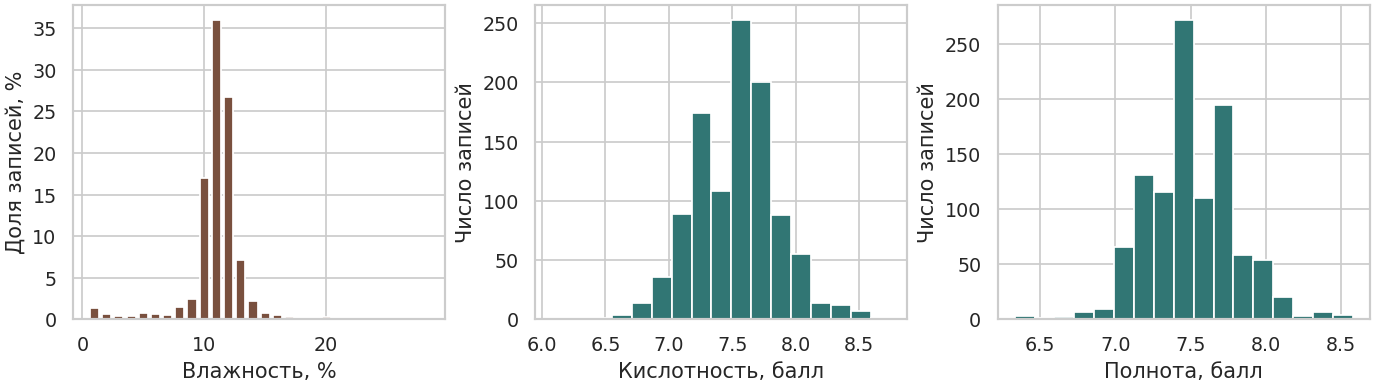

In [3]:
# @title Описательные статистики и графики трёх величин { display-mode: "form" }
show_table(pd.DataFrame({
    name: series.describe(percentiles=[.25,.5,.75])
    for name, series in [("Влажность, %", 100*data.moisture),
                         ("Кислотность, балл", data.acidity), ("Полнота, балл", data.body)]
}).T, 2)

fig, axs = plt.subplots(1, 3, figsize=(11, 3.1), layout="constrained")
pmf = (100*data.moisture).value_counts(normalize=True).sort_index()
axs[0].bar(pmf.index, 100*pmf.values, color="#79503e", width=.75)
axs[0].set(xlabel="Влажность, %", ylabel="Доля записей, %")
for ax, key, label in zip(axs[1:], ["acidity","body"], ["Кислотность, балл","Полнота, балл"]):
    ax.hist(data[key], bins=17, color="#317674", edgecolor="white")
    ax.set(xlabel=label, ylabel="Число записей")
plt.show()

У влажности сильный пик в 11%, а также есть редкие записи по обе стороны от центра. Чтобы увидеть структуру в середине, показываем частоты на увеличенном участке 8–15%, исходные хвосты остаются в расчётах и на полном графике. Для записей ниже и выше границ по правилу $1{,}5\,IQR$ выводим числа отдельно. Это отметка для проверки, а не основание считать измерение ошибочным.

Для сравнения шкал считаем min–max и z-score по всем трём признакам. Первое переводит значения в $[0,1]$, второе вычитает среднее и делит на выборочное стандартное отклонение. Оба преобразования сохраняют порядок и повторы. Например, все записи с влажностью 11% и после стандартизации попадают в одну точку. Сдвиг и растяжение шкалы не исправят этот пик. Отрицательная степень сжала бы верхний хвост и усилила нижний, а на нулях вообще не определена. Для разбора центра достаточно увеличения графика, преобразовывать значения для этого не нужно.

Ниже 7%: 45 строк; выше 15%: 16 строк.
Запросили 10 квантильных групп, получили 5 из-за совпадения границ.


,min после min–max,max после min–max,среднее z,SD z,разных значений до,после z
moisture,0.0,1.0,-0.0,1.0,22,22
acidity,0.0,1.0,0.0,1.0,29,29
body,0.0,1.0,-0.0,1.0,28,28


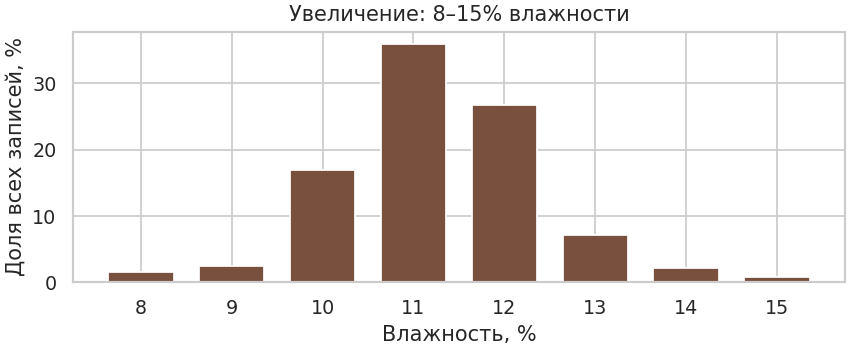

In [ ]:
# @title Стандартизация, центральный участок и десять групп { display-mode: "form" }
x = data[columns]
z = (x-x.mean())/x.std(ddof=1)
mm = (x-x.min())/(x.max()-x.min())
show_table(pd.DataFrame({"min после min–max": mm.min(), "max после min–max": mm.max(),
                         "среднее z": z.mean(), "SD z": z.std(ddof=1),
                         "разных значений до": x.nunique(), "после z": z.nunique()}), 4)

w = 100*data.moisture
q1, q3 = w.quantile([.25,.75])
lo, hi = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
groups10 = pd.qcut(w, 10, duplicates="drop")
print(f"Ниже {lo:g}%: {w.lt(lo).sum()} строк, выше {hi:g}%: {w.gt(hi).sum()} строк.")
print(f"Запросили 10 квантильных групп, получили {groups10.cat.categories.size} из-за совпадения границ.")

fig, ax = plt.subplots(figsize=(6.8, 2.8), layout="constrained")
center = pmf.loc[pmf.index.to_series().between(8,15)]
ax.bar(center.index, 100*center, color="#79503e", width=.72)
ax.set(xticks=range(8,16), xlabel="Влажность, %", ylabel="Доля всех записей, %",
       title="Увеличение: 8–15% влажности")
plt.show()

Десять равных по численности групп здесь не получаются без разрыва одинаковых значений: один только уровень 11% занимает больше трети таблицы. Для сравнения стран используем три понятных диапазона: **ниже 10%, от 10 до 12% включительно, выше 12%**. Границы 10 и 12% - квартили общего поднабора S1, а не стандарт качества или порог годности кофе. Для генератора оставляем все исходные уровни.

## Происхождение, высота и способ обработки

Для сравнения стран берём группы с большим числом записей: Мексику, Гватемалу, Колумбию и Бразилию, Китай показываем отдельно как небольшой пример. В этой сводке влажность сравниваем среди положительных записей арабики из S1, а долю нулей считаем среди всех записей арабики с положительными сенсорными баллами **до** фильтра влажности. Чтобы понять, не объясняется ли различие только составом способов обработки, повторяем сравнение Мексики и Гватемалы на `Washed / Wet`. Это проверка устойчивости, не эксперимент с контролем всех факторов.

,Строк,"Нули, %",n при W > 0,"Среднее W, %","Медиана W, %","Q1, %","Q3, %","W от 10 до 12%, доля в %"
Mexico,236.0,5.93,222.0,12.08,12.0,11.0,13.00,66.67
Guatemala,181.0,3.87,174.0,10.64,11.0,10.0,11.00,93.10
Colombia,183.0,42.08,106.0,10.71,11.0,11.0,11.75,78.30
Brazil,132.0,23.48,101.0,10.76,11.0,11.0,12.00,93.07
China,16.0,12.50,14.0,10.79,10.0,10.0,10.75,92.86


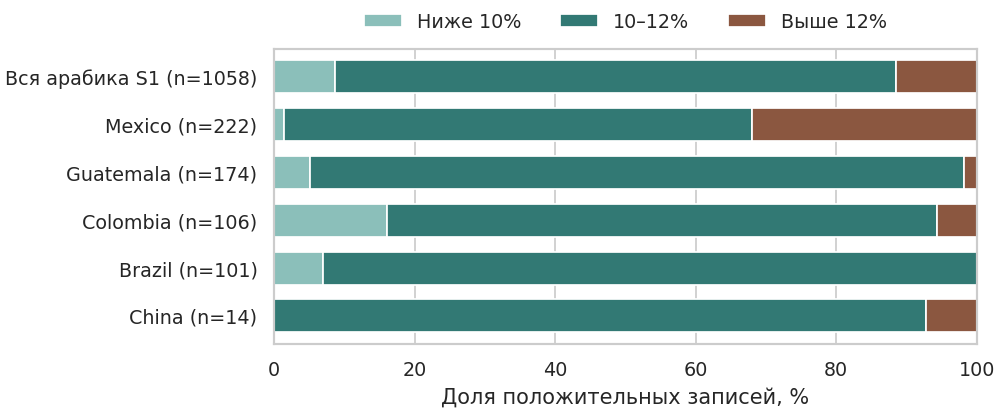

,n при W > 0,"Медиана W, %","W от 10 до 12%, доля в %"
Mexico,187.0,12.0,67.38
Guatemala,156.0,11.0,95.51


В диапазон 10–12% попадает на **26,4 п. п.** больше записей Гватемалы, чем Мексики. Среди записей с мытой обработкой разница составляет **28,1 п. п.**. В Колумбии нули встречаются заметно чаще, поэтому профиль после их исключения описывает только оставшиеся записи.

In [ ]:
# после обработки выбросов
countries = ["Mexico", "Guatemala", "Colombia", "Brazil", "China"]
country_stats = pd.DataFrame({c: moisture_row(base.loc[base.country_of_origin.eq(c)])
                              for c in countries}).T
show_table(country_stats, 2)

fig, ax = plt.subplots(figsize=(8, 3.3), layout="constrained")
comparison_groups = {"Вся арабика S1": data, **{c: data.loc[data.country_of_origin.eq(c)] for c in countries}}
profile = {}
for name, g in comparison_groups.items():
    w = g.moisture
    profile[f"{name} (n={len(w)})"] = 100*np.array([w.lt(.10).mean(), w.between(.10,.12).mean(), w.gt(.12).mean()])
profile = pd.DataFrame(profile, index=["Ниже 10%", "10–12%", "Выше 12%"]).T
profile.plot.barh(stacked=True, color=["#8bbfba", "#327974", "#8b5740"], ax=ax, width=.69)
ax.invert_yaxis()
ax.set(xlim=(0,100), xlabel="Доля положительных записей, %")
ax.legend(loc="lower center", bbox_to_anchor=(.5,1), ncol=3, frameon=False)
plt.show()

wet = base[base.processing_method.eq("Washed / Wet")]
wet_stats = pd.DataFrame({c: moisture_row(wet.loc[wet.country_of_origin.eq(c)])
                           for c in ["Mexico", "Guatemala"]}).T
show_table(wet_stats[["n при W > 0", "Медиана W, %", "W от 10 до 12%, доля в %"]], 2)
wet_diff = wet_stats.iloc[1,-1]-wet_stats.iloc[0,-1]
country_diff = country_stats.loc["Guatemala", "W от 10 до 12%, доля в %"] - country_stats.loc["Mexico", "W от 10 до 12%, доля в %"]
show_md(f"В диапазон 10–12% попадает на **{fmt(country_diff,1)} п. п.** больше записей Гватемалы, "
        f"чем Мексики. Среди записей с мытой обработкой разница составляет **{fmt(wet_diff,1)} п. п.**. "
        "В Колумбии нули встречаются заметно чаще, поэтому профиль после их исключения "
        "описывает только оставшиеся записи.")

### Что даёт поле региона

В Мексике сравниваем наиболее частые исходные метки `region`. Убираем различия регистра и пробелы, но не объединяем вручную названия штата и города: например, `veracruz` и `coatepec` могут относиться к разным уровням географии. Поэтому это сравнение меток в CSV. По нему можно увидеть, что страна сама неоднородна, но нельзя строить вывод о географических границах без словаря регионов.

In [6]:
# @title Мексика: влажность по наиболее частым меткам региона { display-mode: "form" }
region = base.loc[base.country_of_origin.eq("Mexico")].copy()
region["region_label"] = region.region.astype("string").str.strip().str.casefold().replace("",pd.NA)
print(f"Записей без метки региона: {region.region_label.isna().sum()} из {len(region)}.")
top_regions = region.loc[region.moisture.gt(0),"region_label"].value_counts().head(5).index
region_stats = pd.DataFrame({tag: moisture_row(region.loc[region.region_label.eq(tag).fillna(False)])
                             for tag in top_regions}).T
show_table(region_stats[["Строк", "Нули, %", "n при W > 0", "Медиана W, %",
                         "W от 10 до 12%, доля в %"]], 2)

Записей без метки региона: 2 из 236.


,Строк,"Нули, %",n при W > 0,"Медиана W, %","W от 10 до 12%, доля в %"
veracruz,35.0,8.57,32.0,12.0,71.88
coatepec,14.0,0.00,14.0,12.0,71.43
la concordia,12.0,0.00,12.0,11.5,91.67
chiapas,13.0,7.69,12.0,12.0,91.67
zaragoza itundujia,12.0,0.00,12.0,15.0,0.00


### Сравнение высот внутри Мексики

Берём Мексику, потому что среди крупных групп у неё есть достаточно записей во всех трёх диапазонах высоты, а сравнение внутри страны уменьшает смешение со страной. Границы диапазонов задали простыми числами: до 1200 м, от 1200 до 1500 м и от 1500 м. Группы остаются наблюдательными: состав ферм, сортов и способов обработки может различаться.

,country_of_origin,altitude,unit_of_measurement,altitude_mean_meters
543,Brazil,11000 metros,m,11000.0
896,Guatemala,190164,m,190164.0
1040,Nicaragua,1100.00 mosl,m,110000.0
1144,Guatemala,1901.64,m,190164.0


,Нет высоты,Вне окна 300–2500 м
country_of_origin,,
Mexico,4,2
Guatemala,25,8
Colombia,33,6
Brazil,27,15
China,0,0


,Строк,"Нули, %",n при W > 0,"Среднее W, %","Медиана W, %","Q1, %","Q3, %","W от 10 до 12%, доля в %"
Ниже 1200 м,82.0,2.44,80.0,12.16,12.0,11.0,13.0,63.75
1200–1499 м,107.0,6.54,100.0,11.86,12.0,11.0,13.0,72.00
От 1500 м,41.0,7.32,38.0,12.39,12.0,11.0,13.0,63.16


n  Среднее W, %  Медиана W, %
Проверка               Диапазон                                    
Окно 500–2300 м        Ниже 1200 м   79         12.13          12.0
                       1200–1499 м  100         11.86          12.0
                       От 1500 м     38         12.39          12.0
Только мытая обработка Ниже 1200 м   68         12.21          12.0
                       1200–1499 м   82         12.01          12.0
                       От 1500 м     33         12.45          12.0

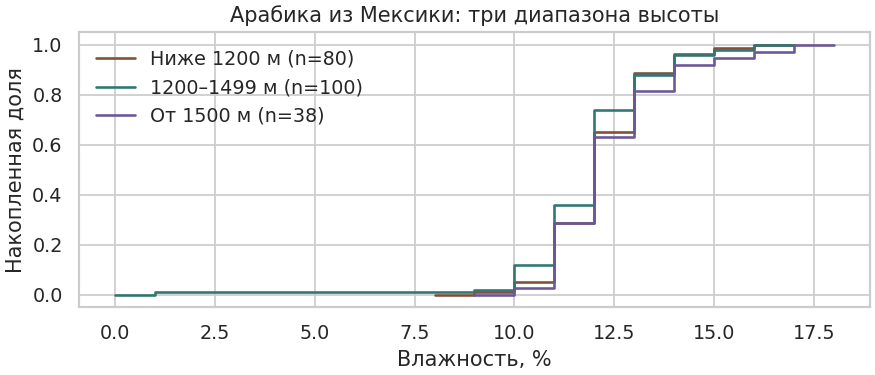

In [7]:
# @title Проверка высоты и сравнение диапазонов { display-mode: "form" }
height = "altitude_mean_meters"
show_table(raw.loc[raw[height].gt(5000), ["country_of_origin","altitude","unit_of_measurement",height]], 1)
height_audit = base.assign(
    missing=base[height].isna(),
    outside=base[height].notna() & ~base[height].between(300,2500),
).groupby("country_of_origin")[["missing","outside"]].sum().reindex(countries)
show_table(height_audit.rename(columns={"missing":"Нет высоты","outside":"Вне окна 300–2500 м"}), 0)

mexico_base = base.loc[base.country_of_origin.eq("Mexico")]
height_levels = ["Ниже 1200 м", "1200–1499 м", "От 1500 м"]

def height_groups(frame, lower, upper):
    subset = frame.loc[frame[height].between(lower,upper)].copy()
    subset["Диапазон"] = pd.cut(subset[height], [-np.inf,1200,1500,np.inf],
                               labels=height_levels, right=False)
    return {level: group for level, group in subset.groupby("Диапазон", observed=True)}

mexico_groups = height_groups(mexico_base,300,2500)
height_stats = pd.DataFrame({k: moisture_row(g) for k,g in mexico_groups.items()}).T
show_table(height_stats, 2)
variants = []
for variant, frame, limits in [("Окно 500–2300 м", mexico_base, (500,2300)),
                                ("Только мытая обработка", mexico_base[mexico_base.processing_method.eq("Washed / Wet")], (300,2500))]:
    for level, g in height_groups(frame,*limits).items():
        a = moisture_row(g)
        variants.append({"Проверка":variant, "Диапазон":level, "n":a["n при W > 0"],
                         "Среднее W, %":a["Среднее W, %"], "Медиана W, %":a["Медиана W, %"]})
show_table(pd.DataFrame(variants).set_index(["Проверка","Диапазон"]), 2)

fig, ax = plt.subplots(figsize=(7,3.0), layout="constrained")
for (level,g),color in zip(mexico_groups.items(), ["#805139","#317674","#6b5797"]):
    vals = 100*g.loc[g.moisture.gt(0),"moisture"]
    s = vals.value_counts(normalize=True).sort_index().cumsum()
    ax.step(np.r_[s.index[0]-1,s.index,s.index[-1]+1], np.r_[0,s.values,1],
            where="post", color=color, label=f"{level} (n={len(vals)})")
ax.set(xlabel="Влажность, %", ylabel="Накопленная доля", title="Арабика из Мексики: три диапазона высоты")
ax.legend(frameon=False)
plt.show()

Медиана в трёх диапазонах одна и та же: 12%. Средние при этом меняются без монотонного порядка, а распределения имеют разные доли отдельных значений. При более узком окне и после ограничения мытой обработкой вывод о медиане сохраняется. На этих данных нет достаточного основания вводить отдельный датчик только по высоте. 

## Связь дегустационных оценок

Вопрос: сохраняется ли связь кислотности с полнотой, если учитывать страну и обработку? Считаем коэффициент Спирмена: сравниваем порядок образцов по двум баллам. Корреляции влажности с оценками приводим для сравнения. Кислотность здесь входит в пару оценок, по корреляции нельзя установить, что она вызывает изменение полноты.

Сначала показываем общий результат по 1058 записям. Затем пересчитываем его внутри стран, отдельно проверяем сохранение связи при включении строк с нулевой влажностью и смотрим, как результат меняется среди образцов одного способа обработки. Аромат добавляем как проверку: сохраняется ли положительная связь между рангами кислотности и полноты после учёта ранга аромата? Это описательное сравнение, потому что аромат оценивается в той же дегустации.

In [ ]:
# @title Корреляции внутри групп
def rho(g, a="acidity", b="body"):
    if len(g) < 3 or g[a].nunique() < 2 or g[b].nunique() < 2:
        return np.nan
    return stats.spearmanr(g[a],g[b]).statistic

association = {"Вся арабика S1":data, **{c:data[data.country_of_origin.eq(c)] for c in countries},
               "S1: только мытая":data[data.processing_method.eq("Washed / Wet")],
               "S1: только сухая":data[data.processing_method.eq("Natural / Dry")]}
show_table(pd.DataFrame({name:{"n":len(g), "ρ: кислотность и полнота":rho(g),
                                "ρ: влажность и кислотность":rho(g,"moisture","acidity"),
                                "ρ: влажность и полнота":rho(g,"moisture","body")}
                         for name,g in association.items()}).T, 3)

ranks = data[["acidity","body","aroma"]].rank().to_numpy()
design = np.column_stack([np.ones(len(data)),ranks[:,2]])
residuals = ranks[:,:2] - design @ np.linalg.lstsq(design,ranks[:,:2],rcond=None)[0]
partial_aroma = np.corrcoef(residuals.T)[0,1]
print(f"Связь кислотности и полноты с включёнными нулями влажности: {fmt(rho(base),3)}.")
print(f"Корреляция ранговых остатков после учёта аромата: {fmt(partial_aroma,3)}.")

Связь кислотности и полноты с включёнными нулями влажности: 0,615.
Корреляция ранговых остатков после учёта аромата: 0,421.


,n,ρ: кислотность и полнота,ρ: влажность и кислотность,ρ: влажность и полнота
Вся арабика S1,1058.0,0.624,-0.180,-0.182
Mexico,222.0,0.515,-0.275,-0.252
Guatemala,174.0,0.650,-0.145,-0.190
Colombia,106.0,0.524,0.309,0.362
Brazil,101.0,0.520,0.025,-0.146
China,14.0,0.816,-0.265,-0.431
S1: только мытая,680.0,0.624,-0.200,-0.143
S1: только сухая,186.0,0.598,-0.159,-0.193


**Проверка гипотезы.** $H_0$: кислотность и полнота независимы внутри страны. $H_1$: существует зависимость. Для каждой страны с хотя бы двумя записями (среди строк с указанной страной) ранжируем баллы внутри неё, вычитаем средний ранг в каждой группе и делим на стандартное отклонение рангов. Группы с постоянным баллом исключаем: корреляция в них не определена. Статистика - модуль корреляции объединённых стандартизованных рангов. Веса групп в ней пропорциональны числу записей.

При $H_0$ и обменности строк внутри страны допустимо переставлять полноту только внутри страны. Считаем долю перестановок со статистикой не меньше наблюдаемой и используем поправку $p=(r+1)/(B+1)$. Предположение обменности может нарушаться, если строки одной фермы похожи. Поэтому дополнительно проверяем, сохраняется ли знак при оценке целых ферм. Кластерный бутстрэп отвечает за устойчивость оценки на строках с указанной фермой, это не тот же перестановочный тест.

In [ ]:
# Оценка ферм
groups = []
for _,g in data.groupby("country_of_origin"):
    z_g = g[["acidity","body"]].rank().to_numpy()
    sd = z_g.std(axis=0)
    if len(g) > 1 and np.all(sd > 0):
        groups.append((z_g-z_g.mean(axis=0))/sd)
rstack = np.vstack(groups)
observed = np.mean(rstack[:,0]*rstack[:,1])
rng = np.random.default_rng(SEED+32)
B = 1999
extreme = sum(abs(sum(g[:,0] @ rng.permutation(g[:,1]) for g in groups)/len(rstack))
              >= abs(observed)-1e-12 for _ in range(B))
p_country = (extreme+1)/(B+1)

def clean_label(s):
    return s.astype("string").str.strip().str.casefold().str.replace(r"\s+", " ", regex=True)

farm = clean_label(data.farm_name)
country = clean_label(data.country_of_origin)
generic = r"^(?:various|varios|varias|several|multiple|mixed|unknown|none|n/?a|not specified|\d+)(?:$|\s)"
ok = farm.notna() & country.notna() & farm.ne("") & ~farm.str.contains(generic,regex=True,na=False)
f = data.loc[ok,["acidity","body"]].copy().reset_index(drop=True)
f["farm_group"] = (country[ok] + " | " + farm[ok]).to_numpy()
idx = list(f.groupby("farm_group").indices.values())
fv = f[["acidity","body"]].to_numpy()
rng = np.random.default_rng(SEED+33)
boot = []
for _ in range(1000):
    inds = np.concatenate([idx[i] for i in rng.integers(len(idx),size=len(idx))])
    boot.append(stats.spearmanr(fv[inds,0],fv[inds,1]).statistic)
ci = np.quantile(boot,[.025,.975])

show_md(f"Внутри стран: объединённый коэффициент **{fmt(observed,3)}**, "
        f"перестановочное **p = {fmt(p_country,4)}** (n = {len(rstack)}). "
        f"При уровне 0,05 и допущении обменности {('отвергаем' if p_country < .05 else 'не отвергаем')} H₀. "
        f"По {len(idx)} фермам ({len(f)} строк) 95%-й кластерный бутстрэп-интервал Спирмена: "
        f"**[{fmt(ci[0],3)}, {fmt(ci[1],3)}]**.")

Внутри стран: объединённый коэффициент **0,556**, перестановочное **p = 0,0005** (n = 1049). При уровне 0,05 и допущении обменности отвергаем H₀. По 489 фермам (753 строк) 95%-й кластерный бутстрэп-интервал Спирмена: **[0,608; 0,701]**.

## Отбор строк и точность оценок

Для этого сравнения **модельная генеральная совокупность** - положительные записи арабики из четырёх крупных стран, перечисленных выше. У каждой страны свой размер группы. Среднее для всей модельной таблицы взвешиваем по исходным долям стран $N_h/N$, иначе оценивали бы среднее четырёх стран с одинаковым весом.

Для анализа реальных записей выбираем отбор без возвращения: в каждой группе нужна выборка разных строк. Для сравнения моделируем также отбор с возвращением при тех же размерах. В стране с $N_h$ записями и $n_h$ извлечениями стандартная ошибка при отборе без возвращения в $\sqrt{(N_h-n_h)/(N_h-1)}$ раза меньше (если дисперсию таблицы считаем с делителем $N_h$). Это свойство схемы отбора. Одна конкретная выборка без возвращения всё равно может дать менее точное среднее, чем одна выборка с возвращением.

In [ ]:
# Стратифицированный отбор
sample_groups = {c: data.loc[data.country_of_origin.eq(c),columns].to_numpy()
                 for c in countries[:4]}
rng = np.random.default_rng(SEED+51)
m, reps = 30, 1000
rows, sim_wr, sim_wor, targets, weights_n, truth_variances = [], [], [], [], [], []
for name, v in sample_groups.items():
    N_h = len(v)
    assert N_h >= m
    truth = v.mean(axis=0)
    w_idx = rng.choice(N_h,m,replace=True)
    wo_idx = rng.choice(N_h,m,replace=False)
    wr = v[rng.choice(N_h,(reps,m),replace=True)].mean(axis=1)
    wor = np.array([v[rng.choice(N_h,m,replace=False)].mean(axis=0) for _ in range(reps)])
    wr_se = v[:,0].std(ddof=0)/np.sqrt(m)
    fpc = np.sqrt((N_h-m)/(N_h-1))
    rows.append({"Страна":name,"N":N_h,"n":m,"Уникальных WR":np.unique(w_idx).size,
                 "W в таблице, %":100*truth[0],"W, WR, %":100*v[w_idx,0].mean(),
                 "W, WOR, %":100*v[wo_idx,0].mean(),
                 "SE WR, п. п.":100*wr_se,"SE WOR, п. п.":100*wr_se*fpc})
    sim_wr.append(wr)
    sim_wor.append(wor)
    targets.append(truth)
    weights_n.append(N_h)
    truth_variances.append(v.var(axis=0,ddof=0)/m)
sample_table = pd.DataFrame(rows).set_index("Страна")
show_table(sample_table, 3)

weight = np.asarray(weights_n)/sum(weights_n)
target = np.einsum("h,hj->j",weight,targets)
wr_all = np.einsum("h,hrj->rj",weight,sim_wr)
wor_all = np.einsum("h,hrj->rj",weight,sim_wor)
units = np.array([100,1,1])
exact_wr = np.sqrt(np.einsum("h,hj->j",weight**2,truth_variances))*units
finite = (np.asarray(weights_n)-m)/(np.asarray(weights_n)-1)
exact_wor = np.sqrt(np.einsum("h,hj->j",weight**2*finite,truth_variances))*units
show_table(pd.DataFrame({
    "Среднее совокупности":target*units,
    "SE WR (теория)":exact_wr, "SE WOR (теория)":exact_wor,
    "RMSE WR (повторы)":np.sqrt(((wr_all-target)**2).mean(axis=0))*units,
    "RMSE WOR (повторы)":np.sqrt(((wor_all-target)**2).mean(axis=0))*units,
},index=["Влажность, % (ошибка в п. п.)","Кислотность, балл","Полнота, балл"]),3)
show_md(f"Для взвешенного среднего влажности SE без возвращения меньше на "
        f"**{fmt(100*(1-exact_wor[0]/exact_wr[0]),1)}%** по расчёту. "
        "В повторных выборках сравниваем ошибку оценок с уже известным средним четырёх стран.")

,N,n,Уникальных WR,"W в таблице, %","W, WR, %","W, WOR, %","SE WR, п. п.","SE WOR, п. п."
Страна,,,,,,,,
Mexico,222,30,28,12.077,12.233,12.133,0.274,0.255
Guatemala,174,30,28,10.638,9.633,10.233,0.279,0.254
Colombia,106,30,28,10.708,10.200,10.667,0.519,0.442
Brazil,101,30,24,10.762,11.000,10.767,0.364,0.307


,Среднее совокупности,SE WR (теория),SE WOR (теория),RMSE WR (повторы),RMSE WOR (повторы)
"Влажность, % (ошибка в п. п.)",11.201,0.169,0.151,0.172,0.156
"Кислотность, балл",7.506,0.025,0.023,0.026,0.023
"Полнота, балл",7.472,0.023,0.021,0.023,0.021


Для взвешенного среднего влажности SE без возвращения меньше на **10,7%** по расчёту. В повторных выборках сравниваем ошибку оценок с уже известным средним четырёх стран.

Отдельно проверяем тот же принцип для высоты. Для мексиканских записей в рабочем окне берём по 15 разных положительных строк из каждого диапазона и сравниваем их с полными подгруппами. Здесь показываем, насколько одна небольшая выборка передаёт не только среднее, но и разброс. Дисперсии совокупности и выборки в этой сводке - описательные, обе с делителем на размер соответствующей таблицы.

In [ ]:
# Стратифицированная выборка внутри Мексики по высоте
rng = np.random.default_rng(SEED+52)
rows_height = []
for level, g in mexico_groups.items():
    w = 100*g.loc[g.moisture.gt(0),"moisture"].to_numpy()
    chosen = rng.choice(w, size=15, replace=False)
    rows_height.append({"Диапазон":level,"N":len(w),"n":len(chosen),
                        "Среднее группы, %":w.mean(),"Среднее выборки, %":chosen.mean(),
                        "Дисперсия группы, п. п.²":w.var(),"Дисперсия выборки, п. п.²":chosen.var()})
show_table(pd.DataFrame(rows_height).set_index("Диапазон"), 2)

,N,n,"Среднее группы, %","Среднее выборки, %","Дисперсия группы, п. п.²","Дисперсия выборки, п. п.²"
Диапазон,,,,,,
Ниже 1200 м,80,15,12.16,11.93,1.44,2.20
1200–1499 м,100,15,11.86,11.73,2.88,0.73
От 1500 м,38,15,12.39,12.60,2.13,1.71


### Состоятельность: что проверяем отдельно

Отбор без возвращения используем для работы с конечной таблицей. Для демонстрации состоятельности берём другой эксперимент: независимые выборки с возвращением из фиксированной эмпирической модели этих четырёх стран. Здесь можно увеличивать $n$, даже если оно превысит число строк: повторения не являются новыми измерениями кофе.

По закону больших чисел выборочное среднее приближается к $E[X]$. Для исправленной дисперсии используем запись $s^2=\frac{n}{n-1}(\overline{X^2}-\bar X^2)$. Оба средних сходятся к своим ожиданиям, а $n/(n-1)$ стремится к 1. Так получаем сходимость к $E[X^2]-E[X]^2$. В таблице ниже только результаты независимых симуляций по 1000 повторений для каждого размера.

In [ ]:
# Компактная проверка состоятельности
pool = np.concatenate(list(sample_groups.values()),axis=0)
rng = np.random.default_rng(SEED+61)
consistency = []
for m_try in (20,100,500,2000):
    drawn = pool[rng.integers(len(pool),size=(1000,m_try))]
    err_mu = (drawn.mean(axis=1)-pool.mean(axis=0))*units
    err_var = (drawn.var(axis=1,ddof=1)-pool.var(axis=0,ddof=0))*units**2
    rmse_mu = np.sqrt(np.mean(err_mu**2,axis=0))
    rmse_var = np.sqrt(np.mean(err_var**2,axis=0))
    consistency.append([m_try,*rmse_mu,*rmse_var])
labels_c = ["n","Среднее W","Среднее A","Среднее B","Дисперсия W","Дисперсия A","Дисперсия B"]
show_table(pd.DataFrame(consistency,columns=labels_c).set_index("n"),4)

,Среднее W,Среднее A,Среднее B,Дисперсия W,Дисперсия A,Дисперсия B
n,,,,,,
20,0.4457,0.0563,0.0576,3.3659,0.0252,0.0245
100,0.1987,0.0262,0.0259,1.3896,0.0114,0.0109
500,0.0923,0.0119,0.0108,0.6518,0.0046,0.0048
2000,0.0435,0.0060,0.0058,0.3154,0.0024,0.0026


В таблице RMSE для среднего влажности выражен в процентных пунктах, для двух оценок - в баллах. Для дисперсий единицы возводятся в квадрат. С ростом размера типичная ошибка уменьшается. Эти повторы проверяют, как работают оценки в выбранной модели, а не представительность исходных записей.

## Распределение для генератора

Для заданной группы из $N$ строк считаем $c_i$ - сколько раз встретилось значение $x_i$. Тогда $p_i=c_i/N$, а $F(t)=\sum_{x_i\le t}p_i$. Это ступенчатая функция распределения записанных величин. Для генератора влажности хранить нужно все наблюдавшиеся значения и их доли, а не три диапазона с графика.

Из этих же частот можно посчитать параметры модели: $\mu=\sum_i x_i p_i$ и $\sigma^2=\sum_i(x_i-\mu)^2p_i$. Для влажности в общем поднаборе $\mu=11{,}00\%$, а стандартное отклонение $\sigma$ - около 2,28 п. п. Дисперсия модели - это дисперсия всей её таблицы с делителем $N$, при оценке по случайной выборке используем исправленную дисперсию с делителем $n-1$.

В приложении сохранена проверка нормальной и логистической моделей с округлением до 0,01. Она оценивает сочетание «форма распределения + правило записи», а не позволяет восстановить точность измерения. Границы для кислотности и полноты в этом приближении - 0–10 баллов. При выборе модели для генератора также важнее воспроизвести пики влажности и разницу по происхождению, чем найти гладкую кривую с меньшим AIC.

In [ ]:
# Влажность: сравнение условных распределений с общим
support = np.sort(data.moisture.unique())
def aligned_cdf(series):
    return series.value_counts(normalize=True).reindex(support,fill_value=0).cumsum().to_numpy()
whole = aligned_cdf(data.moisture)
comparison_s2 = []
for country in countries:
    g = data[data.country_of_origin.eq(country)].moisture
    comparison_s2.append({"Страна":country,"n":len(g),
                          "Макс. разница CDF, п. п.":100*np.max(np.abs(aligned_cdf(g)-whole)),
                          "P(10–12%), %":100*g.between(.10,.12).mean()})
show_table(pd.DataFrame(comparison_s2).set_index("Страна"),2)
print(f"Общее P(10–12%): {fmt(100*data.moisture.between(.10,.12).mean(),2)}%.")

Общее P(10–12%): 79,77%.


,n,"Макс. разница CDF, п. п.","P(10–12%), %"
Страна,,,
Mexico,222,29.74,66.67
Guatemala,174,20.46,93.10
Colombia,106,12.81,78.30
Brazil,101,11.85,93.07
China,14,45.72,92.86


Разница CDF здесь - описательная величина: общий профиль включает и ту страну, с которой его сравниваем. По этой разнице не проверяем статистическую гипотезу.

## Выводы

1. **Если происхождение известно, для генератора стоит учитывать страну.** В положительных записях из Мексики доля влажности 10–12% около 67%, (хахахахах типо смешно SIIIIXXX - SEEEVEEEEN) из Гватемалы - около 93%. При сравнении только мытой обработки разница сохраняется. Для имитации записи без заданной страны общий эмпирический профиль S1 остаётся осмысленным. Для новой партии за пределами CSV переносимость такого датчика ещё не проверялась.
2. **Высоту пока не делаем входом генератора.** В трёх диапазонах внутри Мексики медиана 12%, средние меняются без последовательного роста или падения. Смена рабочего окна и отбор только мытой обработки не меняют вывода о медиане. Отдельный датчик для робусты по этому набору пока тоже не обосновываем: даже в Уганде в общей полосе высот всего четыре подходящие записи робусты.
3. **Связь кислотности и полноты сохраняется при сравнении внутри стран.** Общий Спирмен - 0,624, а корреляция остатков рангов после учёта аромата - 0,421. При этом связь самой влажности с кислотностью в Мексике отрицательная, а в Колумбии положительная. Поэтому общий коэффициент влажности не стоит переносить на каждую страну. Баллы получены при дегустации, и этот анализ не доказывает причинность.
4. **Для выборки реальных записей выбираем стратифицированный отбор без возвращения.** Он сохраняет представительство выбранных стран и уменьшает стандартную ошибку при одинаковом числе извлечений. Повторный отбор с возвращением оставляем для демонстрации свойств оценок.

Итоговое применение: можно получить реалистичную **для этой таблицы** серию зарегистрированных влажностей с заданным происхождением. Это годится для моделирования частот в S2, но не для прогноза качества или назначения норм хранения.

## Источники

- [Coffee Quality Database - Джеймс Леду](https://github.com/jldbc/coffee-quality-database): происхождение данных и дата сбора, [скрипт подготовки](https://github.com/jldbc/coffee-quality-database/blob/master/clean_coffee_data.R) показывает перевод влажности в долю.
- [TidyTuesday: Coffee Ratings](https://rfordatascience.github.io/tidytuesday/data/2020/2020-07-07/readme.html): словарь CSV и переименование признаков робусты.
- [International Coffee Organization, Coffee Development Report 2020, блок C.5](https://www.ico.org/wp-content/uploads/2022/11/CDR2020.pdf): сбор и послеуборочная обработка.
- [Руководство CQI для Q Graders, 2021](https://database.coffeeinstitute.org/api/s3proxy/get/coffee/files/tcw319675p/Guidelines%20for%20Q%20Graders%20Participating%20in%20Evaluations%20of%20Q%20Coffees%20v1.0%20Jan%202021.pdf): оборудование для оценки зелёного кофе и отдельные протоколы для арабики и робусты.
- [ISO 6673:2003](https://www.iso.org/standard/38375.html): пример метода определения потери массы зелёного кофе при 105 °C.
- [Протокол каппинга SCAA, редакция 2015 года](https://www.coffeecloud.one/coffee-cupping/docs/cupping-protocols.pdf): подготовка арабики, критерии дегустации и подсчёт баллов.
- [CQI / UCDA: Fine Robusta Standards and Protocols](https://www.scith.coffee/wp-content/uploads/2021/03/Fine-Robusta-Standards-Protocols.pdf): отдельная форма оценки робусты.
- [Cornell INFO 2950: Coffee Ratings](https://pages.github.coecis.cornell.edu/info2950-s23/project-skillful-hitmontop/proposal.html), учебный анализ того же набора: медиана влажности по 1339 строкам - 11%, среднее после округления - около 9%. Ниже пересчитываем эту сводку на нашем CSV.
- [N. Shpaner: анализ качества кофе по данным CQI](https://github.com/nshpaner/coffee_project): другой открытый разбор задаёт вопрос о высоте и обработке одновременно. Здесь мы рассматриваем влажность и приводим сравнения в сопоставимых подгруппах.
- [Worku и соавт., Food Research International, 2018](https://pubmed.ncbi.nlm.nih.gov/29433216/): отдельное исследование арабики, где рассматриваются высота, затенение и послеуборочная обработка. Оно мотивирует проверять сочетание факторов, результаты из этой статьи на наши группы не переносим.

In [ ]:
# таблица участников
total = 100*raw.moisture
nonzero = total[total.gt(0)]
print(f"Полный CSV: среднее {fmt(total.mean(),2)}%, медиана {fmt(total.median(),0)}%, "
      f"после удаления только {(total==0).sum()} нулей среднее {fmt(nonzero.mean(),2)}%.")
print("Среднее полного CSV при округлении до целых совпадает со сводкой Cornell.")
cat_mark_table = pd.DataFrame(TEAM).assign(notebook_link=NOTEBOOK_URL)
cat_mark_table["comment"] = cat_mark_table["name"]+" / "+cat_mark_table["github"]
show_table(cat_mark_table[["cat_id","notebook_link","coeff","comment"]],2)

Полный CSV: среднее 8,84%, медиана 11%; после удаления только 264 нулей среднее 11,01%.
Среднее полного CSV при округлении до целых совпадает со сводкой Cornell.


,cat_id,notebook_link,coeff,comment
0,502585,https://github.com/Mironiks007/fifty-shades-of-coffee-stat/blob/main/stat-lab1-s1.ipynb,0.5,Петров Мирон / Mironiks007
1,501572,https://github.com/Mironiks007/fifty-shades-of-coffee-stat/blob/main/stat-lab1-s1.ipynb,0.5,Каплунова Анна / kaplunovaania


## Приложение

### Две модели распределения с округлением

Для сопоставления с исходной версией S1 сохраняем проверку нормального и логистического законов для трёх признаков в общем поднаборе арабики. Если скрытое значение имеет CDF $G_\theta$, а наблюдаемое округлено с шагом $\delta=0{,}01$, вероятность записи $x$ равна $G_\theta(x+\delta/2)-G_\theta(x-\delta/2)$. Подбираем параметры по этим вероятностям. При вычислении правдоподобия используем исходные доли влажности и баллы.

Сравниваем функции распределения по максимальной абсолютной разнице, включая левые пределы скачков. Генерируем 499 выборок из каждой подогнанной модели, округляем их и заново оцениваем параметры. Это приближённая проверка с допущением независимых строк, для шести сравнений применяем поправку Холма. Оценки из таблицы и варианты правила их записи не известны с такой точностью, чтобы результат считать проверкой «истинного закона» физической величины.

In [ ]:
# Сравнение нормальной и логистической моделей
"""Проверяем приближение: непрерывное распределение и простое округление до 0,01."""
import numpy as np
from scipy import stats, optimize

def rounded_fit(x, family, step=0.01):
    """Оцениваем параметры распределения по значениям, записанным на сетке."""
    x = np.asarray(x, dtype=float)
    support, counts = np.unique(x, return_counts=True)
    center, unit = x.mean(), x.std(ddof=0)
    dist = getattr(stats, family)
    loc0, scale0 = dist.fit(x)
    def negative_log_likelihood(theta):
        loc = center + unit * theta[0]
        scale = unit * np.exp(theta[1])
        lower = (support - step / 2 - loc) / scale
        upper = (support + step / 2 - loc) / scale
        probability = np.where(lower >= 0,
                               dist.sf(lower) - dist.sf(upper),
                               dist.cdf(upper) - dist.cdf(lower))
        return -np.dot(counts, np.log(np.maximum(probability, np.finfo(float).tiny)))
    start = [(loc0-center)/unit, np.log(scale0/unit)]
    result = optimize.minimize(negative_log_likelihood, start, method='L-BFGS-B',
                               bounds=[(-10,10),(-6,4)], options={'ftol':1e-10})
    if not result.success:
        result = optimize.minimize(negative_log_likelihood, start, method='Powell',
                                   bounds=[(-10,10),(-6,4)])
    if not result.success or not np.isfinite(result.fun):
        raise RuntimeError('Distribution fit did not converge: ' + result.message)
    loc = center + unit * result.x[0]
    scale = unit * np.exp(result.x[1])
    return float(loc), float(scale), float(-result.fun)

def rounded_cdf_distance(x, family, loc, scale, step=0.01):
    support, counts = np.unique(x, return_counts=True)
    right = np.cumsum(counts) / len(x)
    left = right - counts / len(x)
    dist = getattr(stats, family)
    model_right = dist.cdf((support + step/2 - loc)/scale)
    model_left = dist.cdf((support - step/2 - loc)/scale)
    return max(np.max(np.abs(right-model_right)), np.max(np.abs(left-model_left)))


fitted_model_rows = []
fitted_parameters = {}
model_rng = np.random.default_rng(SEED + 610)
model_repetitions = 499
for column in columns:
    values = data[column].to_numpy()
    for family in ["norm", "logistic"]:
        loc, scale, log_likelihood = rounded_fit(values, family)
        observed_D = rounded_cdf_distance(values, family, loc, scale)
        extreme = 0
        for _ in range(model_repetitions):
            latent = (model_rng.normal(loc, scale, len(values)) if family == "norm" else
                      model_rng.logistic(loc, scale, len(values)))
            simulated = np.round(latent, 2)
            sim_loc, sim_scale, _ = rounded_fit(simulated, family)
            extreme += rounded_cdf_distance(simulated, family, sim_loc, sim_scale) >= observed_D - 1e-12
        p_mc = (extreme+1)/(model_repetitions+1)
        lower, upper = (0,1) if column == "moisture" else (0,10)
        dist = getattr(stats, family)
        fitted_parameters[(column,family)] = (loc,scale)
        fitted_model_rows.append({"variable":column, "family":family, "loc":loc, "scale":scale,
            "log_likelihood":log_likelihood, "AIC":4-2*log_likelihood,
            "CDF_distance":observed_D, "p_MC":p_mc,
            "latent_mass_outside_physical_scale":dist.cdf((lower-loc)/scale)+dist.sf((upper-loc)/scale)})
fitted_model_table = pd.DataFrame(fitted_model_rows)
fitted_model_table["p_Holm_6"] = holm_adjust(fitted_model_table["p_MC"])
fitted_model_table["reject_model"] = fitted_model_table["p_Holm_6"] < ALPHA

shown = fitted_model_table.set_index(["variable","family"])[["AIC","CDF_distance","p_MC","p_Holm_6","reject_model"]]
show_table(shown,4)
print(f"Отвергнуто моделей: {fitted_model_table.reject_model.sum()} из {len(shown)}.")

Отвергнуто моделей: 6 из 6.


AIC  CDF_distance   p_MC  p_Holm_6  reject_model
variable family                                                           
moisture norm       4749.1810        0.1666  0.002     0.012          True
         logistic   4322.1327        0.0802  0.002     0.012          True
acidity  norm      10299.6853        0.0690  0.002     0.012          True
         logistic  10267.9605        0.0566  0.002     0.012          True
body     norm      10098.5937        0.0710  0.002     0.012          True
         logistic  10068.3522        0.0690  0.002     0.012          True